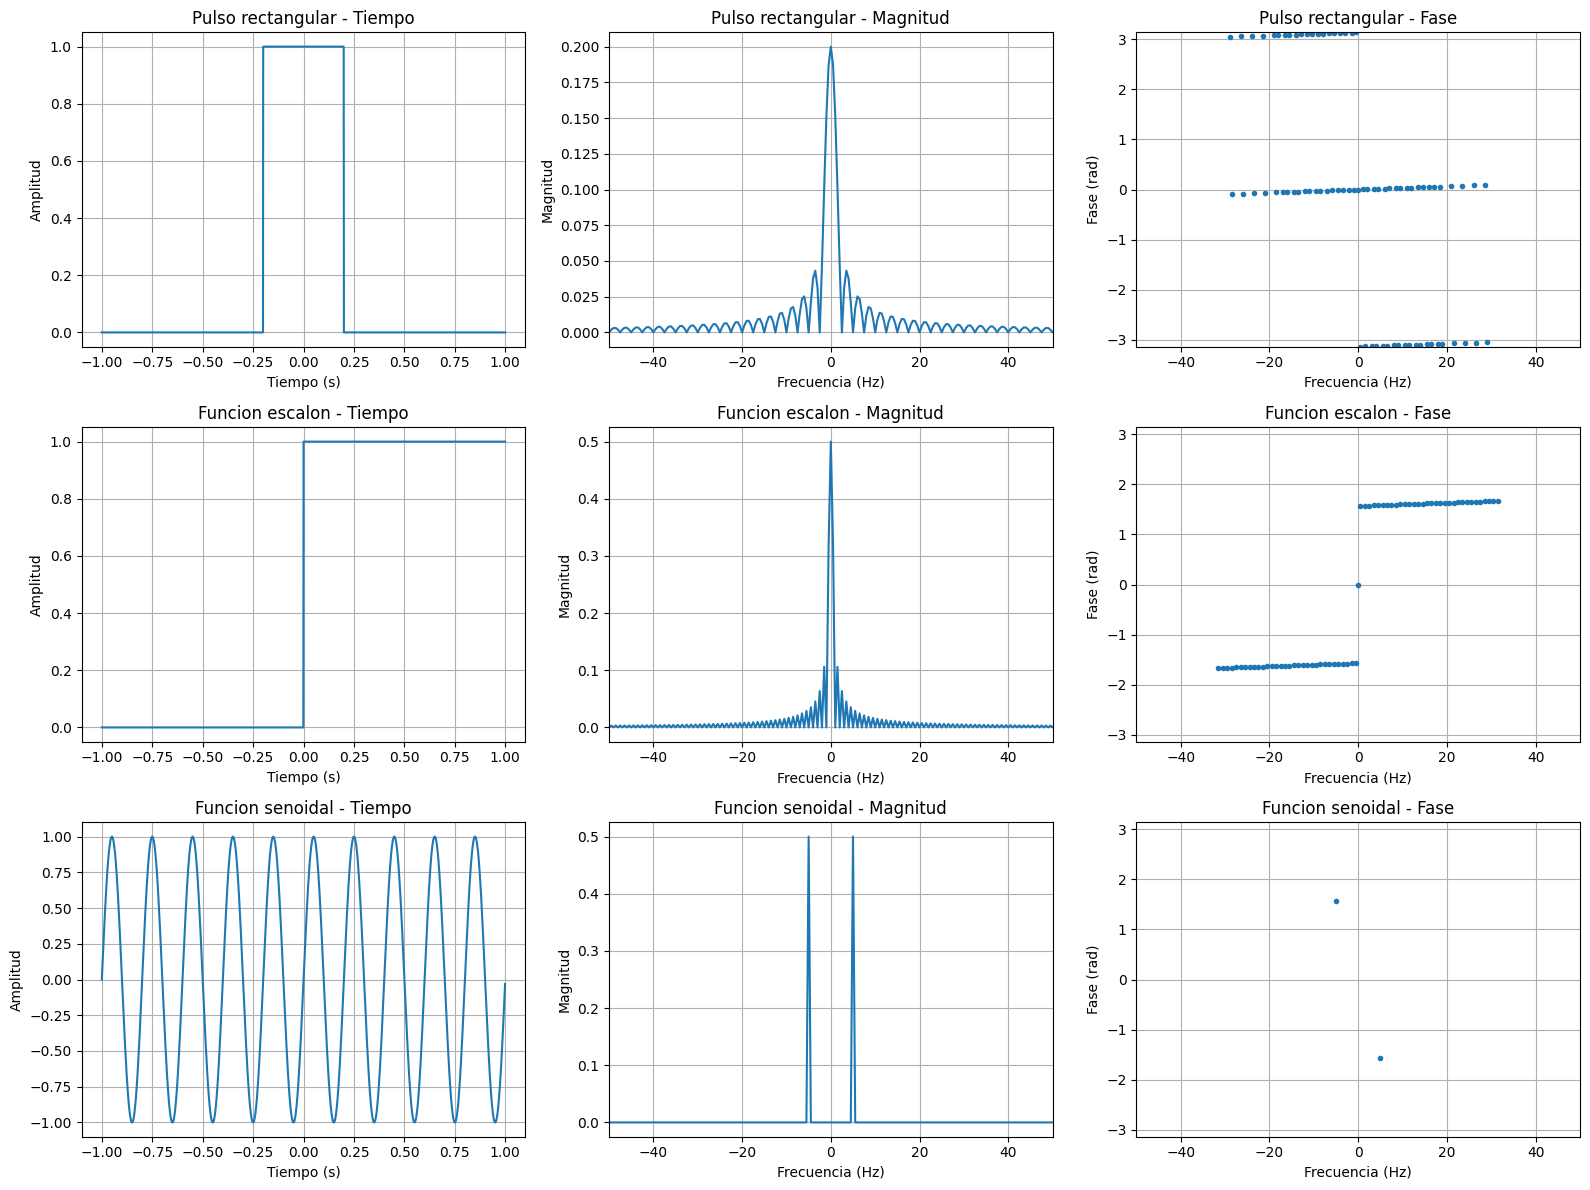

Comprobacion de linealidad
Error numerico: 4.772371903672579e-13
Resultado: se cumple la propiedad de linealidad.

Comprobacion del desplazamiento temporal
Diferencia maxima entre magnitudes: 1.1368683772161603e-13

Simulacion finalizada.


In [ ]:

# ACTIVIDAD: ANALISIS DE SENALES Y TRANSFORMADA DE FOURIER
# Autor: Escribe aqui tu nombre
# Objetivo: Analizar tres senales en el dominio del tiempo
# y estudiar sus componentes en el dominio de la frecuencia.

import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. CONFIGURACION DE LA SIMULACION
# --------------------------------------------------

fs = 1000                 # Frecuencia de muestreo en Hz
T = 2                     # Duracion de la simulacion en segundos
t = np.arange(-1, 1, 1/fs)

N = len(t)

# --------------------------------------------------
# 2. GENERACION DE LAS SENALES
# --------------------------------------------------

# Senal 1: pulso rectangular
pulso = np.where(np.abs(t) <= 0.2, 1.0, 0.0)

# Senal 2: funcion escalon unitario
escalon = np.where(t >= 0, 1.0, 0.0)

# Senal 3: funcion senoidal de 5 Hz
f0 = 5
senoidal = np.sin(2 * np.pi * f0 * t)

senales = {
    "Pulso rectangular": pulso,
    "Funcion escalon": escalon,
    "Funcion senoidal": senoidal
}

# --------------------------------------------------
# 3. TRANSFORMADA DE FOURIER
# --------------------------------------------------

frecuencias = np.fft.fftshift(np.fft.fftfreq(N, d=1/fs))

espectros = {}

for nombre, senal in senales.items():
    # Transformada rapida de Fourier
    X = np.fft.fftshift(np.fft.fft(senal))

    # Magnitud normalizada
    magnitud = np.abs(X) / N

    # Fase en radianes
    fase = np.angle(X)

    espectros[nombre] = (magnitud, fase)

# --------------------------------------------------
# 4. GRAFICAS EN TIEMPO Y FRECUENCIA
# --------------------------------------------------

fig, ejes = plt.subplots(3, 3, figsize=(16, 12))

for fila, (nombre, senal) in enumerate(senales.items()):
    magnitud, fase = espectros[nombre]

    # Dominio del tiempo
    ejes[fila, 0].plot(t, senal)
    ejes[fila, 0].set_title(nombre + " - Tiempo")
    ejes[fila, 0].set_xlabel("Tiempo (s)")
    ejes[fila, 0].set_ylabel("Amplitud")
    ejes[fila, 0].grid(True)

    # Espectro de magnitud
    ejes[fila, 1].plot(frecuencias, magnitud)
    ejes[fila, 1].set_xlim(-50, 50)
    ejes[fila, 1].set_title(nombre + " - Magnitud")
    ejes[fila, 1].set_xlabel("Frecuencia (Hz)")
    ejes[fila, 1].set_ylabel("Magnitud")
    ejes[fila, 1].grid(True)

    # Espectro de fase
    mascara = magnitud > 0.005
    ejes[fila, 2].plot(
        frecuencias[mascara],
        fase[mascara],
        "."
    )
    ejes[fila, 2].set_xlim(-50, 50)
    ejes[fila, 2].set_ylim(-np.pi, np.pi)
    ejes[fila, 2].set_title(nombre + " - Fase")
    ejes[fila, 2].set_xlabel("Frecuencia (Hz)")
    ejes[fila, 2].set_ylabel("Fase (rad)")
    ejes[fila, 2].grid(True)

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 5. COMPROBACION DE LA PROPIEDAD DE LINEALIDAD
# --------------------------------------------------

x1 = senoidal
x2 = np.sin(2 * np.pi * 10 * t)

a = 2
b = 3

transformada_combinada = np.fft.fft(a*x1 + b*x2)
transformadas_separadas = (
    a*np.fft.fft(x1) + b*np.fft.fft(x2)
)

error = np.max(
    np.abs(transformada_combinada - transformadas_separadas)
)

print("Comprobacion de linealidad")
print("Error numerico:", error)

if error < 1e-9:
    print("Resultado: se cumple la propiedad de linealidad.")

# --------------------------------------------------
# 6. COMPROBACION DEL DESPLAZAMIENTO TEMPORAL
# --------------------------------------------------

desplazamiento = 0.1
muestras_desplazamiento = int(desplazamiento * fs)

senal_desplazada = np.roll(
    senoidal, muestras_desplazamiento
)

X_original = np.fft.fft(senoidal)
X_desplazada = np.fft.fft(senal_desplazada)

print("\nComprobacion del desplazamiento temporal")
print(
    "Diferencia maxima entre magnitudes:",
    np.max(np.abs(np.abs(X_original) - np.abs(X_desplazada)))
)

print("\nSimulacion finalizada.")


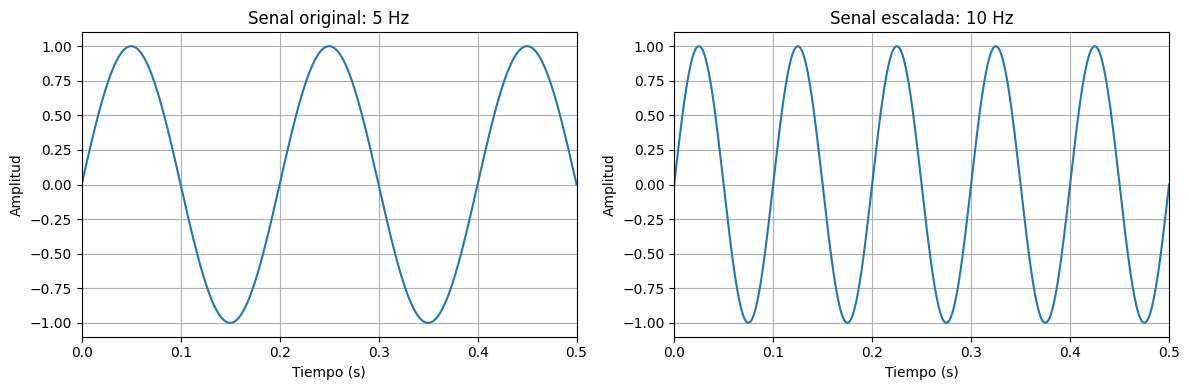

In [ ]:

# COMPROBACION DEL ESCALAMIENTO EN FRECUENCIA

fs = 1000
t2 = np.arange(-1, 1, 1/fs)

# Senal original de 5 Hz
x_original = np.sin(2 * np.pi * 5 * t2)

# Senal con frecuencia duplicada: 10 Hz
x_escalada = np.sin(2 * np.pi * 10 * t2)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(t2, x_original)
plt.xlim(0, 0.5)
plt.title("Senal original: 5 Hz")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(t2, x_escalada)
plt.xlim(0, 0.5)
plt.title("Senal escalada: 10 Hz")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.grid(True)

plt.tight_layout()
plt.show()
